# Apple Stock

### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [31]:
import pandas as pd
import numpy as np
from datetime import datetime
from pandas.tseries.offsets import DateOffset, BDay
import matplotlib.pyplot as plt

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [2]:
url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv"
df = pd.read_csv(url)

### Step 3. Assign it to a variable apple and apply a head()

In [3]:
apple = df.copy()

apple.head()

,Date,Open,High,Low,Close,Volume,Adj Close
0,2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
1,2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2,2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
3,2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
4,2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 4.  Check out the type of the columns

In [5]:
apple.dtypes

Date             str
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object

### Step 5. Transform the Date column as a datetime type and check the info()

In [6]:
apple["Date"] = pd.to_datetime(apple["Date"])

apple.info()

<class 'pandas.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       8465 non-null   datetime64[us]
 1   Open       8465 non-null   float64       
 2   High       8465 non-null   float64       
 3   Low        8465 non-null   float64       
 4   Close      8465 non-null   float64       
 5   Volume     8465 non-null   int64         
 6   Adj Close  8465 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 463.1 KB


In [8]:
apple.tail()

,Date,Open,High,Low,Close,Volume,Adj Close
8460,1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41
8461,1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
8462,1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
8463,1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
8464,1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45


### Step 6.  Set the date as the index

In [ ]:
apple = apple.set_index(["Date"])
apple.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 7.  Is there any duplicate dates?

In [11]:
apple.index.duplicated().sum()

np.int64(0)

In [12]:
apple.index.is_unique

True

### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [15]:
apple = apple.sort_index()

apple.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41


### Step 9. Get the last business day of each month

In [25]:
last_bdays = pd.date_range(start=apple.index.min(), end=apple.index.max(), freq="BME")

print(last_bdays)

apple[apple.index.isin(last_bdays)]

DatetimeIndex(['1980-12-31', '1981-01-30', '1981-02-27', '1981-03-31',
               '1981-04-30', '1981-05-29', '1981-06-30', '1981-07-31',
               '1981-08-31', '1981-09-30',
               ...
               '2013-09-30', '2013-10-31', '2013-11-29', '2013-12-31',
               '2014-01-31', '2014-02-28', '2014-03-31', '2014-04-30',
               '2014-05-30', '2014-06-30'],
              dtype='datetime64[us]', length=403, freq='BME')


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-31,34.25,34.25,34.13,34.13,8937600,0.53
1981-01-30,28.50,28.50,28.25,28.25,11547200,0.44
1981-02-27,26.50,26.75,26.50,26.50,3690400,0.41
1981-03-31,24.75,24.75,24.50,24.50,3998400,0.38
1981-04-30,28.38,28.62,28.38,28.38,3152800,0.44
...,...,...,...,...,...,...
2014-02-28,529.08,532.75,522.12,526.24,92992200,74.76
2014-03-31,539.23,540.81,535.93,536.74,42167300,76.25
2014-04-30,592.64,599.43,589.80,590.09,114160200,83.83


### Step 10.  What is the difference in days between the first day and the oldest

In [27]:
(apple.index.max() - apple.index.min()).days

12261

### Step 11.  How many months in the data we have?

In [ ]:
apple.index.to_period("M").nunique() # El to_period("M") lo pone en formato "1980-12"

404

In [30]:
apple.index.to_period("M")

PeriodIndex(['1980-12', '1980-12', '1980-12', '1980-12', '1980-12', '1980-12',
             '1980-12', '1980-12', '1980-12', '1980-12',
             ...
             '2014-06', '2014-06', '2014-06', '2014-06', '2014-06', '2014-07',
             '2014-07', '2014-07', '2014-07', '2014-07'],
            dtype='period[M]', name='Date', length=8465)

### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

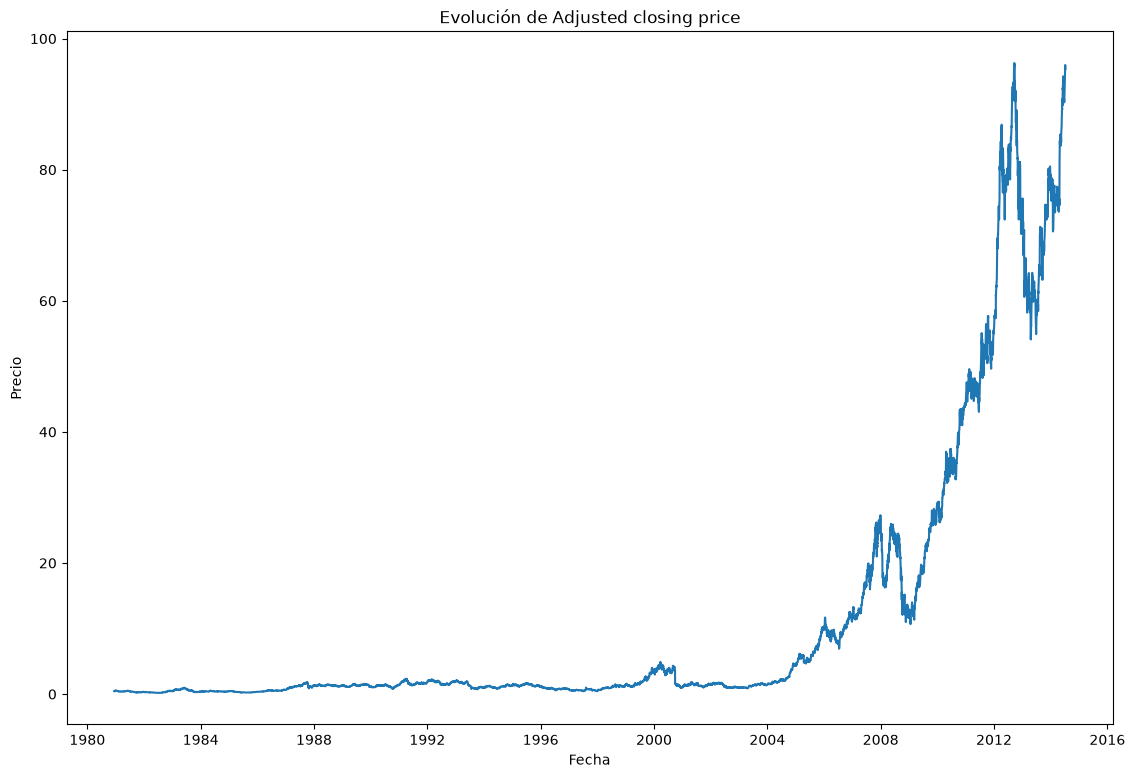

In [36]:
plt.figure(figsize=(13.5, 9))
plt.plot(apple["Adj Close"])
plt.title("Evolución de Adjusted closing price")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

In [40]:
import plotly.express as px

fig = px.line(
    apple, 
    x=apple.index, 
    y="Adj Close", 
    title="Evolución de Adjusted closing price",
    labels={"index": "Fecha", "Adj Close": "Precio"},
    range_x=["1980-01-01", "2016-12-31"] 
)

fig.update_layout(
    height=860
)

fig.show()